# SYDE572 Assignment 2
## Linear Regression

**Name:** Shiva Arya

This report contains the results for polynomial and Gaussian basis function regression using the Boston Housing dataset.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("housing.data")

X = data[:, :-1]
y = data[:, -1]

X_train = X[:100]
y_train = y[:100]

X_test = X[100:]
y_test = y[100:]

mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

std[std == 0] = 1

X_train_n = (X_train - mean) / std
X_test_n = (X_test - mean) / std

def polynomial_features(X, degree):
    features = []

    for d in range(1, degree + 1):
        features.append(X ** d)

    return np.hstack(features)

## Part 1(a) - Polynomial Regression

Polynomial regression models with degrees 1 to 7 were fitted using the first 100 data points as training data and the remaining points as test data. No regularization was used.

In [3]:
train_errors = []
test_errors = []

for degree in range(1, 8):
    Phi_train = polynomial_features(X_train_n, degree)
    Phi_test = polynomial_features(X_test_n, degree)

    Phi_train = np.column_stack((np.ones(len(Phi_train)), Phi_train))
    Phi_test = np.column_stack((np.ones(len(Phi_test)), Phi_test))

    w = np.linalg.pinv(Phi_train) @ y_train

    y_train_pred = Phi_train @ w
    y_test_pred = Phi_test @ w

    train_rms = np.sqrt(np.mean((y_train_pred - y_train) ** 2))
    test_rms = np.sqrt(np.mean((y_test_pred - y_test) ** 2))

    train_errors.append(train_rms)
    test_errors.append(test_rms)

    print(degree, train_rms, test_rms)

1 2.0372006149680435 36.44494988736498
2 1.5780786080891775 1097.1882549619647
3 1.4490980035949013 48672.81779285386
4 1.2704983595451156 21859310.196226984
5 1.0966362623901043 18358040620.027046
6 1.0725098459566127 5024088561185.2
7 0.8814671780633162 6879332108253741.0


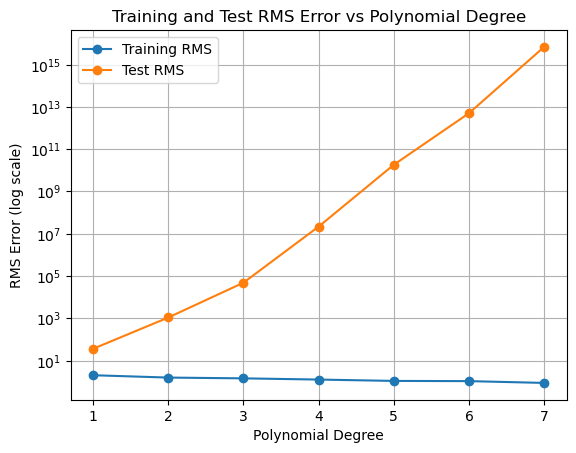

In [4]:
degrees = range(1, 8)

plt.plot(degrees, train_errors, marker='o', label='Training RMS')
plt.plot(degrees, test_errors, marker='o', label='Test RMS')

plt.xlabel('Polynomial Degree')
plt.ylabel('RMS Error (log scale)')
plt.title('Training and Test RMS Error vs Polynomial Degree')
plt.yscale('log')
plt.legend()
plt.grid()

plt.show()

The training RMS error decreases as the polynomial degree increases, showing that higher-degree models fit the training data more closely. However, the test RMS error increases dramatically for higher polynomial degrees. This indicates severe overfitting, where the model becomes too complex and performs poorly on unseen data. The degree-1 model gives the lowest test RMS error among the models tested.

## Part 1(b) - Learned Weights

A degree-1 polynomial regression model was used to examine the learned weights.

In [5]:
Phi_train = polynomial_features(X_train_n, 1)
Phi_train = np.column_stack((np.ones(len(Phi_train)), Phi_train))

w = np.linalg.pinv(Phi_train) @ y_train

for i, weight in enumerate(w):
    print("w", i, "=", weight)

w 0 = 22.30900000000002
w 1 = -1.3379737305573962
w 2 = 0.122993392413145
w 3 = -0.5310646272683706
w 4 = 2.796531494192018e-16
w 5 = 1.0026514165674936
w 6 = 4.195634385830218
w 7 = -2.166274886804982
w 8 = 0.010715449340658711
w 9 = -0.19377822414930512
w 10 = -0.34863096338200605
w 11 = 0.2612640167592568
w 12 = 0.1810730372583863
w 13 = 0.14876112719043277


Because the printed weight vector includes the bias term at index 0, the coefficient for the 6th original feature appears as w[6], and the coefficient for the 8th original feature appears as w[8].

The bias weight is approximately 22.309.

The weight associated with the 6th feature, average number of rooms per dwelling, is approximately 4.196. The positive value is reasonable because a larger number of rooms would generally be associated with a higher house value.

The weight associated with the 8th feature, weighted distance to Boston employment centres, is approximately 0.0107. This value is close to zero, suggesting that this feature has relatively little effect on the prediction after accounting for the other features.

Since the input features were normalized, these weights correspond to standardized feature values rather than the original units.

## Part 1(c) - One-Dimensional Polynomial Regression

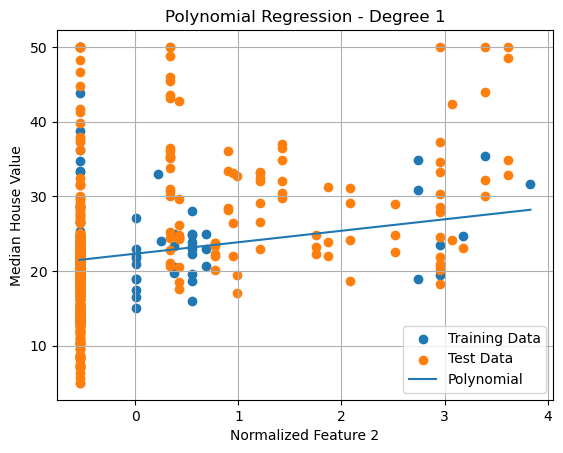

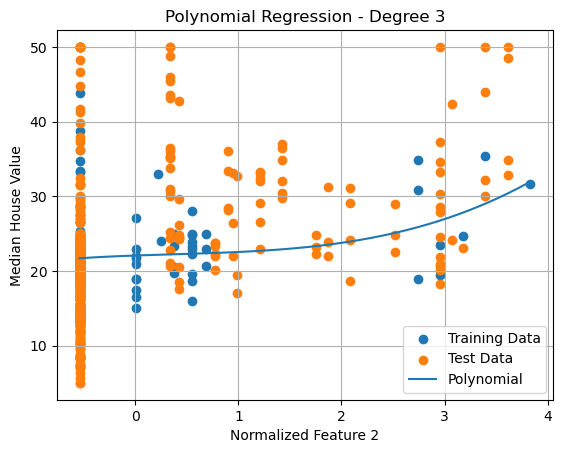

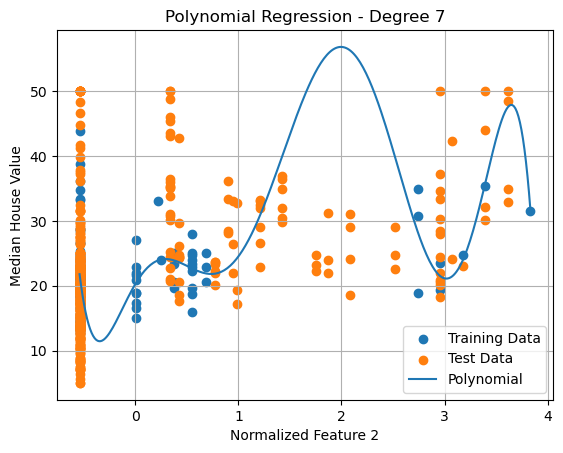

In [6]:
x_train_1d = X_train_n[:, 1]
x_test_1d = X_test_n[:, 1]

degrees_to_plot = [1, 3, 7]

for degree in degrees_to_plot:
    Phi_train = np.column_stack(
        [x_train_1d ** d for d in range(1, degree + 1)]
    )
    Phi_train = np.column_stack((np.ones(len(Phi_train)), Phi_train))

    w = np.linalg.pinv(Phi_train) @ y_train

    x_line = np.linspace(
        min(x_train_1d.min(), x_test_1d.min()),
        max(x_train_1d.max(), x_test_1d.max()),
        300
    )

    Phi_line = np.column_stack(
        [x_line ** d for d in range(1, degree + 1)]
    )
    Phi_line = np.column_stack((np.ones(len(Phi_line)), Phi_line))

    y_line = Phi_line @ w

    plt.figure()

    plt.scatter(x_train_1d, y_train, label='Training Data')
    plt.scatter(x_test_1d, y_test, label='Test Data')

    plt.plot(x_line, y_line, label='Polynomial')

    plt.xlabel('Normalized Feature 2')
    plt.ylabel('Median House Value')
    plt.title(f'Polynomial Regression - Degree {degree}')
    plt.legend()
    plt.grid()

    plt.show()

The degree-1 polynomial produces a simple linear fit and does not capture much variation in the data. The degree-3 model is more flexible and follows the training data more closely. The degree-7 polynomial is much more complex and can show strong curvature, indicating that higher-order models may overfit the training data and behave poorly outside the main training region.

## Part 1(d) - L2 Regularization and Cross-Validation

In [7]:
lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]
degree = 8

validation_errors = []

for lam in lambdas:
    fold_errors = []

    for fold in range(10):
        start = fold * 10
        end = start + 10

        X_val_raw = X_train[start:end]
        y_val = y_train[start:end]

        X_train_fold_raw = np.concatenate(
            (X_train[:start], X_train[end:])
        )

        y_train_fold = np.concatenate(
            (y_train[:start], y_train[end:])
        )

        mean_fold = np.mean(X_train_fold_raw, axis=0)
        std_fold = np.std(X_train_fold_raw, axis=0)

        std_fold[std_fold == 0] = 1

        X_train_fold_n = (X_train_fold_raw - mean_fold) / std_fold
        X_val_n = (X_val_raw - mean_fold) / std_fold

        x_train_fold = X_train_fold_n[:, 1]
        x_val = X_val_n[:, 1]

        Phi_train = np.column_stack(
            [x_train_fold ** d for d in range(1, degree + 1)]
        )

        Phi_train = np.column_stack(
            (np.ones(len(Phi_train)), Phi_train)
        )

        Phi_val = np.column_stack(
            [x_val ** d for d in range(1, degree + 1)]
        )

        Phi_val = np.column_stack(
            (np.ones(len(Phi_val)), Phi_val)
        )

        I = np.eye(Phi_train.shape[1])
        I[0, 0] = 0

        w = np.linalg.pinv(
            Phi_train.T @ Phi_train + lam * I
        ) @ Phi_train.T @ y_train_fold

        y_val_pred = Phi_val @ w

        rms = np.sqrt(
            np.mean((y_val_pred - y_val) ** 2)
        )

        fold_errors.append(rms)

    validation_errors.append(np.mean(fold_errors))

for lam, err in zip(lambdas, validation_errors):
    print(
        "lambda =", lam,
        "average validation RMS =", err
    )

lambda = 0 average validation RMS = 3511.723575981193
lambda = 0.01 average validation RMS = 903.8384600137927
lambda = 0.1 average validation RMS = 109.66558673201659
lambda = 1 average validation RMS = 70.01766793409857
lambda = 10 average validation RMS = 9.983912552178868
lambda = 100 average validation RMS = 12.450721608042713
lambda = 1000 average validation RMS = 17.786931780123314


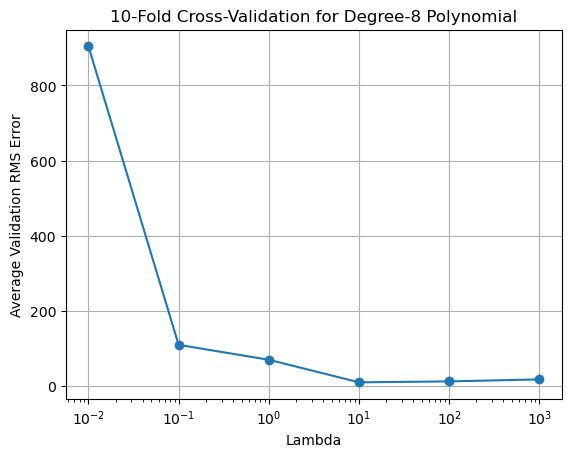

Validation error for lambda = 0: 3511.723575981193


In [8]:
plt.semilogx(
    lambdas[1:],
    validation_errors[1:],
    marker='o'
)

plt.xlabel('Lambda')
plt.ylabel('Average Validation RMS Error')
plt.title('10-Fold Cross-Validation for Degree-8 Polynomial')
plt.grid()

plt.show()

print(
    "Validation error for lambda = 0:",
    validation_errors[0]
)

In [9]:
best_index = np.argmin(validation_errors)

print("Best lambda:", lambdas[best_index])
print("Best validation RMS:", validation_errors[best_index])

Best lambda: 10
Best validation RMS: 9.983912552178868


Using 10-fold cross-validation, the lowest average validation RMS error was approximately 9.98 at $\lambda = 10$. Therefore, $\lambda = 10$ was selected as the regularization parameter for the degree-8 polynomial model. The unregularized model produced a much larger validation error, showing that the high-degree polynomial overfits strongly without regularization. L2 regularization helps control the polynomial coefficients and improves generalization.

## Part 2(e) - Gaussian Basis Function Regression

In [12]:
def gaussian_features(X, centers, sigma=1.0):
    Phi = []

    for center in centers:
        dist2 = np.sum((X - center) ** 2, axis=1)
        Phi.append(np.exp(-dist2 / (2 * sigma ** 2)))

    return np.column_stack(Phi)

In [13]:
np.random.seed(0)

basis_counts = list(range(5, 100, 10))

gaussian_train_errors = []
gaussian_test_errors = []

perm = np.random.permutation(len(X_train_n))

for K in basis_counts:
    center_indices = perm[:K]
    centers = X_train_n[center_indices]

    Phi_train = gaussian_features(X_train_n, centers)
    Phi_test = gaussian_features(X_test_n, centers)

    Phi_train = np.column_stack((np.ones(len(Phi_train)), Phi_train))
    Phi_test = np.column_stack((np.ones(len(Phi_test)), Phi_test))

    w = np.linalg.pinv(Phi_train) @ y_train

    train_pred = Phi_train @ w
    test_pred = Phi_test @ w

    train_rms = np.sqrt(np.mean((train_pred - y_train) ** 2))
    test_rms = np.sqrt(np.mean((test_pred - y_test) ** 2))

    gaussian_train_errors.append(train_rms)
    gaussian_test_errors.append(test_rms)

    print(K, train_rms, test_rms)

5 5.091595257332708 9.803085078721478
15 5.003758834649999 9.803463254231822
25 4.301958559698613 9.801184386677434
35 3.6062981058307306 9.779893709425075
45 3.3518215643436577 9.838753593671186
55 2.7897187726321175 9.863483457764948
65 2.3716396859626427 10.181098269710011
75 1.1904239982726725 9.986942501983554
85 1.0644290212027374 10.301855792815916
95 0.8763800188503571 11.18613464085074


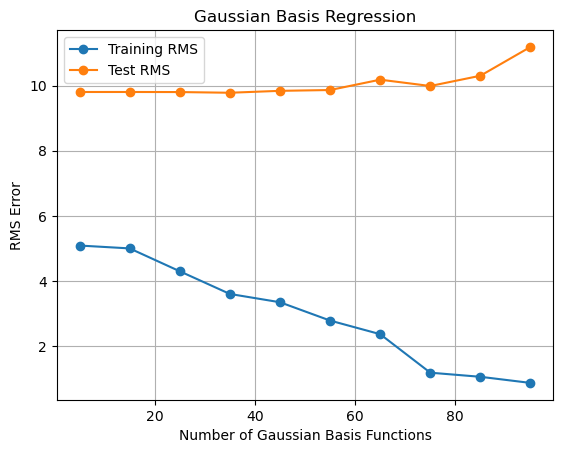

In [14]:
plt.plot(
    basis_counts,
    gaussian_train_errors,
    marker='o',
    label='Training RMS'
)

plt.plot(
    basis_counts,
    gaussian_test_errors,
    marker='o',
    label='Test RMS'
)

plt.xlabel('Number of Gaussian Basis Functions')
plt.ylabel('RMS Error')
plt.title('Gaussian Basis Regression')
plt.legend()
plt.grid()

plt.show()

As the number of Gaussian basis functions increases, the training RMS error generally decreases because the model becomes more flexible and can fit the training data more closely. However, the test RMS error does not decrease in the same way and begins to increase when many basis functions are used. This suggests overfitting: increasing the number of Gaussian basis functions improves the training fit but does not necessarily improve generalization to unseen data.

## Part 2(f) - Regularized Gaussian Regression

In [18]:
lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]

validation_errors_gaussian = []

for lam in lambdas:
    fold_errors = []

    for fold in range(10):
        start = fold * 10
        end = start + 10

        X_val_raw = X_train[start:end]
        y_val = y_train[start:end]

        X_train_fold_raw = np.concatenate(
            (X_train[:start], X_train[end:])
        )

        y_train_fold = np.concatenate(
            (y_train[:start], y_train[end:])
        )

        mean_fold = np.mean(X_train_fold_raw, axis=0)
        std_fold = np.std(X_train_fold_raw, axis=0)

        std_fold[std_fold == 0] = 1

        X_train_fold_n = (X_train_fold_raw - mean_fold) / std_fold
        X_val_n = (X_val_raw - mean_fold) / std_fold

        centers = X_train_fold_n

        Phi_train = gaussian_features(X_train_fold_n, centers)
        Phi_val = gaussian_features(X_val_n, centers)

        Phi_train = np.column_stack(
            (np.ones(len(Phi_train)), Phi_train)
        )

        Phi_val = np.column_stack(
            (np.ones(len(Phi_val)), Phi_val)
        )

        I = np.eye(Phi_train.shape[1])
        I[0, 0] = 0

        w = np.linalg.pinv(
            Phi_train.T @ Phi_train + lam * I
        ) @ Phi_train.T @ y_train_fold

        y_val_pred = Phi_val @ w

        rms = np.sqrt(
            np.mean((y_val_pred - y_val) ** 2)
        )

        fold_errors.append(rms)

    validation_errors_gaussian.append(
        np.mean(fold_errors)
    )

for lam, err in zip(lambdas, validation_errors_gaussian):
    print(
        "lambda =", lam,
        "average validation RMS =", err
    )

lambda = 0 average validation RMS = 5.084142343584134
lambda = 0.01 average validation RMS = 4.781418327322204
lambda = 0.1 average validation RMS = 4.738156460101235
lambda = 1 average validation RMS = 4.844802488323449
lambda = 10 average validation RMS = 5.230489057755489
lambda = 100 average validation RMS = 5.576598384755984
lambda = 1000 average validation RMS = 5.665360211141218


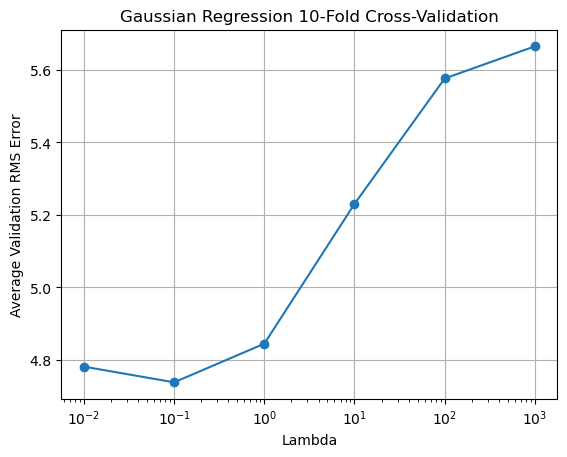

Validation error for lambda = 0: 5.084142343584134


In [19]:
plt.semilogx(
    lambdas[1:],
    validation_errors_gaussian[1:],
    marker='o'
)

plt.xlabel('Lambda')
plt.ylabel('Average Validation RMS Error')
plt.title('Gaussian Regression 10-Fold Cross-Validation')
plt.grid()

plt.show()

print(
    "Validation error for lambda = 0:",
    validation_errors_gaussian[0]
)

In [20]:
best_index = np.argmin(validation_errors_gaussian)

print("Best lambda:", lambdas[best_index])
print(
    "Best validation RMS:",
    validation_errors_gaussian[best_index]
)

Best lambda: 0.1
Best validation RMS: 4.738156460101235


Using 10-fold cross-validation, the value of $\lambda$ with the lowest average validation RMS error was selected for the regularized Gaussian basis regression model. The unregularized model produced a higher validation error, while moderate L2 regularization improved validation performance. Stronger regularization beyond the best value increased the validation error.